# 03 · Partición temporal y baselines

**Encargo (hueco 4):** prever la intensidad diaria de tráfico a 7 días en ~200 puntos urbanos de Madrid para
planificar obras en vía urbana.

Con la serie construida y entendida (notebooks 01 y 02), este notebook cubre los apartados **C**, **D** y **E**:
1. **Partición temporal**: última semana como prueba y validación con **ventana rodante**.
2. **Baselines** con StatsForecast: media, naïve, seasonal naïve y drift.
3. **Evaluación** con MAE, RMSE y MASE, en la prueba y en la ventana rodante.
4. **Rival a batir** en cada serie y dónde falla.
5. **Residuos** del mejor baseline y **plan para E2**.

Siguiendo el handout, en E1 se evalúan **el total y una muestra de 10 sensores**; al final se comprueba que la
conclusión se mantiene en los 200.

In [1]:
import sys
from functools import partial
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import HistoricAverage, Naive, RandomWalkWithDrift, SeasonalNaive
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, mase, rmse


def _raiz() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        for c in (p, p / "e1"):
            if (c / "src" / "descarga_bruto.py").exists():
                return c
    raise FileNotFoundError("No encuentro e1/src/descarga_bruto.py")


RAIZ = _raiz()
sys.path.insert(0, str(RAIZ / "src"))
import serie_diaria as sd  # noqa: E402

H = 7                 # horizonte del encargo: 7 días
ESTACION = 7          # season_length: ciclo semanal (notebook 02)
N_VENTANAS = 52       # orígenes de la ventana rodante: un año de semanas
PASO = 7              # días entre un origen y el siguiente

AZUL, NARANJA, ROJO, VERDE, GRIS = "#4C72B0", "#DD8452", "#C44E52", "#55A868", "#BBBBBB"
MODELOS = {"HistoricAverage": "Media", "Naive": "Naïve", "SeasonalNaive": "Seasonal naïve", "RWD": "Drift"}
COLOR = {"Media": VERDE, "Naïve": NARANJA, "Seasonal naïve": AZUL, "Drift": ROJO}
NOMBRES = list(MODELOS.values())

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Las series

Se reconstruye la serie diaria con `src/serie_diaria.py` (notebook 02) y se preparan las 11 series de E1 en formato
largo: el **total** y la **muestra de 10 sensores** repartidos por nivel de tráfico.

In [2]:
serie = sd.construir()
train_200, test_200 = sd.partir(serie)
MUESTRA = sd.muestra(train_200, n=10)

# Valores reales que faltan en la semana de test (días con fallo: no se imputan, se excluyen de la evaluación)
faltan = test_200[test_200["y"].isna()]
print(f"Sensor-días sin dato real en la semana de test: {len(faltan)} de {len(test_200)} "
      f"(sensores {sorted(faltan['unique_id'].unique())})")

total = sd.total(serie)
print(f"El total suma los {total.attrs['sensores']} sensores con la semana de test completa.")

df = pd.concat([total, serie.loc[serie["unique_id"].isin(MUESTRA), ["unique_id", "ds", "y"]]], ignore_index=True)
SERIES = ["TOTAL", *MUESTRA]
df.groupby("unique_id")["y"].agg(["count", "mean", "min", "max"]).loc[SERIES]

Sensor-días sin dato real en la semana de test: 4 de 1400 (sensores ['10945', '5746'])
El total suma los 198 sensores con la semana de test completa.


,count,mean,min,max
unique_id,,,,
TOTAL,730,"53,202.74","25,626.06","72,727.93"
5683,730,29.95,12.67,60.40
6353,730,68.49,13.69,105.86
6126,730,92.39,34.05,140.61
4835,730,132.13,39.44,436.88
10910,730,170.04,76.95,241.72
3484,730,214.09,47.89,524.07
11011,730,277.11,103.65,449.09
5924,730,368.79,179.43,634.75


**Decisión sobre el total.** En la semana de test, dos sensores tienen algún día con fallo y por tanto sin valor
real. Sumar 200 sensores unos días y 199 otros daría un total que no es comparable de un día a otro. Por eso el total
se calcula con los **198 sensores que tienen la semana de test completa**, tanto en entrenamiento como en prueba.
Esto solo usa de la semana de test el hecho de que el dato exista, no su valor. Ninguno de los dos sensores está en la
muestra de 10.

## 2. Partición temporal

| | Desde | Hasta | Días |
|---|---|---|---|
| **Entrenamiento** | 1 nov 2024 | 24 oct 2026 | 723 |
| **Prueba** | 25 oct 2026 | 31 oct 2026 | 7 |

**Por qué este corte.**
- La prueba es **exactamente un horizonte del encargo** (7 días) y son los **últimos** días disponibles: es la
  situación real, en la que se predice la semana que viene con todo lo anterior.
- Una semana completa contiene los siete días de la semana, así que la prueba cubre el ciclo semanal entero.
- El corte es **por fecha**, nunca aleatorio: todo el entrenamiento es anterior a toda la prueba.

**Límite.** Una sola semana es poca evidencia, y la del 25 al 31 de octubre de 2026 es una semana normal, sin
festivos. Por sí sola no dice cómo se comportan los métodos en una semana con festivo o en agosto. Para eso está la
ventana rodante de la sección 3.

In [3]:
train = df[df["ds"] < sd.TEST_INICIO].reset_index(drop=True)
test = df[df["ds"] >= sd.TEST_INICIO].reset_index(drop=True)

# Comprobaciones de que no hay fuga de información
assert train["ds"].max() < test["ds"].min(), "Hay solape entre entrenamiento y prueba"
assert test.groupby("unique_id")["ds"].count().eq(H).all(), "La prueba no es un horizonte completo"
assert train["y"].notna().all() and test["y"].notna().all()
# La imputación solo mira hacia atrás: rehacer la serie SIN la semana de test da el mismo entrenamiento
print("Último día de entrenamiento:", train["ds"].max().date(), "· primer día de prueba:", test["ds"].min().date())
print("Días de prueba por serie:", H, "· series:", train["unique_id"].nunique())

Último día de entrenamiento: 2026-10-24 · primer día de prueba: 2026-10-25
Días de prueba por serie: 7 · series: 11


**Nada del futuro entra en el entrenamiento.** Cuatro puntos donde podría colarse y cómo está resuelto:

| Dónde podría haber fuga | Cómo se evita |
|---|---|
| Elección de los 200 sensores | Se hizo en el notebook 01 con datos anteriores al 25 de octubre de 2026 |
| Reglas de calidad y umbrales | Se fijaron en el notebook 01 mirando solo entrenamiento |
| **Imputación de días con fallo** | Cada hueco se rellena con el último valor válido del **mismo día de la semana anterior**: solo usa el pasado. Los días con fallo de la semana de test no se imputan |
| Variables externas | No se usa ninguna en E1 |

El tercer punto importa también para la ventana rodante: como la imputación nunca mira hacia delante, cualquier corte
intermedio del entrenamiento sigue estando limpio.

## 3. Validación con ventana rodante

Se repite el ejercicio de la prueba muchas veces dentro del entrenamiento: se corta en un sábado, se predicen los 7
días siguientes, se avanza una semana y se vuelve a empezar. Cada corte es un **origen**.

- **52 orígenes**, uno por semana, que cubren el **último año** del entrenamiento (25 oct 2025 – 17 oct 2026). El
  mínimo que pide la entrega son 3; se usan 52 porque así la evaluación pasa por todas las épocas del año: Navidad,
  Semana Santa, agosto y los festivos.
- **Ventana expansiva**: en cada origen se entrena con todo lo anterior. El primer origen dispone ya de un año de
  histórico.
- **Paso de 7 días**: las ventanas no se solapan y cada día del último año se predice exactamente una vez.

Orígenes: 52 · primero: 2025-10-25 · último: 2026-10-17
Días predichos por serie: 364


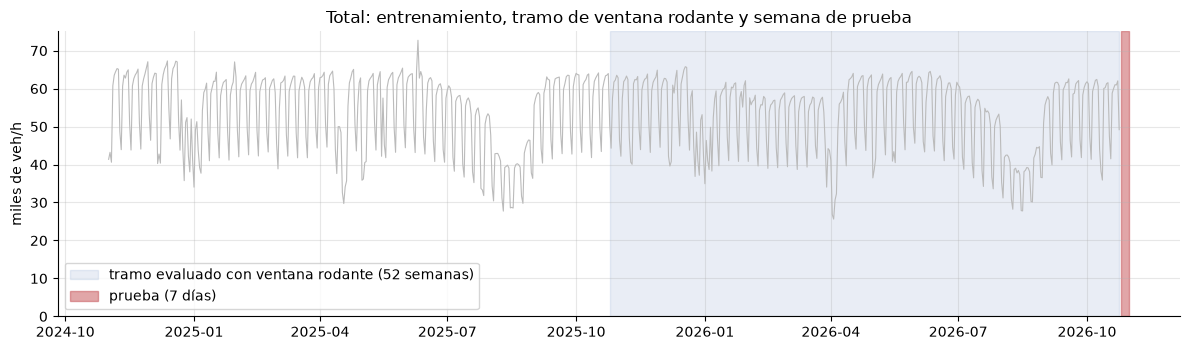

In [4]:
sf = StatsForecast(
    models=[HistoricAverage(), Naive(), SeasonalNaive(season_length=ESTACION), RandomWalkWithDrift()],
    freq="D",
)
cv = sf.cross_validation(df=train, h=H, step_size=PASO, n_windows=N_VENTANAS).rename(columns=MODELOS)
origenes = np.sort(cv["cutoff"].unique())
print(f"Orígenes: {len(origenes)} · primero: {pd.Timestamp(origenes[0]).date()} · último: {pd.Timestamp(origenes[-1]).date()}")
print(f"Días predichos por serie: {cv.groupby('unique_id')['ds'].nunique().iloc[0]}")
assert (cv["ds"] > cv["cutoff"]).all(), "Alguna predicción es anterior a su origen"

t = train[train["unique_id"] == "TOTAL"].set_index("ds")["y"] / 1e3
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(t.index, t, color=GRIS, linewidth=0.8)
ax.axvspan(pd.Timestamp(origenes[0]), t.index[-1], color=AZUL, alpha=0.12, label="tramo evaluado con ventana rodante (52 semanas)")
ax.axvspan(sd.TEST_INICIO, sd.FIN, color=ROJO, alpha=0.5, label="prueba (7 días)")
ax.set(title="Total: entrenamiento, tramo de ventana rodante y semana de prueba", ylabel="miles de veh/h")
ax.set_ylim(0, None)
ax.legend(loc="lower left")
plt.tight_layout()

## 4. Baselines

Cuatro métodos sin parámetros que ajustar. Son el listón: un modelo de E2 solo merece la pena si los supera.

| Método | Qué predice para los próximos 7 días | Qué supone |
|---|---|---|
| **Media** (`HistoricAverage`) | La media de todo el histórico | Que el tráfico no tiene patrón: siempre el nivel medio |
| **Naïve** | El valor del último día conocido | Que mañana será como hoy |
| **Seasonal naïve** (`season_length = 7`) | El valor del mismo día de la semana pasada | Que la semana que viene será como esta |
| **Drift** (`RandomWalkWithDrift`) | El último valor más la pendiente media del histórico | Que continúa la tendencia de largo plazo |

**`season_length = 7`.** El notebook 02 muestra que el ciclo dominante es el semanal (autocorrelación de 0,74 a 7
días; sábado −23 % y domingo −31 %). La estacionalidad anual existe, pero con menos de dos años no hay dos ciclos
completos de 365 días, y un seasonal naïve anual copiaría el mismo día del año pasado, que cae en otro día de la
semana.

### Las métricas

- **MAE**: error medio en veh/h. Se lee directamente en las unidades de la serie.
- **RMSE**: como el MAE, pero penaliza más los errores grandes. Si es mucho mayor que el MAE, hay días con fallos
  muy gordos.
- **MASE**: el MAE dividido por el MAE que tiene, **dentro del entrenamiento**, un seasonal naïve de 7 días. No tiene
  unidades, así que permite comparar una calle de 30 veh/h con un eje de 700. **Menor que 1** significa que se predice
  mejor que el error habitual de copiar la semana anterior.

En la ventana rodante el MASE se calcula **origen a origen**, escalando con el entrenamiento disponible en ese
origen y no con el entrenamiento completo, para que la escala tampoco use información posterior al corte.

In [5]:
METRICAS = [mae, rmse, partial(mase, seasonality=ESTACION)]


def evaluar(pred: pd.DataFrame, entrenamiento: pd.DataFrame) -> pd.DataFrame:
    "MAE, RMSE y MASE por serie y modelo. El MASE se escala con `entrenamiento`."
    return evaluate(pred, metrics=METRICAS, train_df=entrenamiento, models=NOMBRES)


# --- Prueba: se entrena con todo el entrenamiento y se predicen los 7 días apartados
pred_test = sf.forecast(df=train, h=H, fitted=True).rename(columns=MODELOS)
ajustados = sf.forecast_fitted_values().rename(columns=MODELOS)   # se usan en la sección 6
ev_test = evaluar(test.merge(pred_test, on=["unique_id", "ds"]), train)

# --- Ventana rodante: una evaluación por origen, con el entrenamiento que había en ese origen
partes = []
for origen in origenes:
    ventana = cv[cv["cutoff"] == origen].drop(columns="cutoff")
    e = evaluar(ventana, train[train["ds"] <= origen])
    partes.append(e.assign(cutoff=origen))
ev_origen = pd.concat(partes, ignore_index=True)
ev_cv = ev_origen.groupby(["unique_id", "metric"])[NOMBRES].mean().reset_index()
print(f"Evaluaciones en ventana rodante: {len(ev_origen):,} (series × métricas × orígenes)")

Evaluaciones en ventana rodante: 1,716 (series × métricas × orígenes)


In [6]:
def tabla(ev: pd.DataFrame, uid: str) -> pd.DataFrame:
    return ev[ev["unique_id"] == uid].set_index("metric")[NOMBRES].loc[["mae", "rmse", "mase"]]


resumen_total = pd.concat({"Prueba (1 semana)": tabla(ev_test, "TOTAL"),
                           "Ventana rodante (52 semanas)": tabla(ev_cv, "TOTAL")})
nivel = train.loc[train["unique_id"] == "TOTAL", "y"].mean()
print(f"TOTAL · nivel medio en entrenamiento: {nivel:,.0f} veh/h")
print("MAE en la ventana rodante como % del nivel medio:",
      {m: f"{v / nivel:.1%}" for m, v in tabla(ev_cv, "TOTAL").loc["mae"].items()})
resumen_total.style.format("{:,.2f}").highlight_min(axis=1, color="#CFE3F5")

TOTAL · nivel medio en entrenamiento: 53,178 veh/h
MAE en la ventana rodante como % del nivel medio: {'Media': '15.8%', 'Naïve': '20.0%', 'Seasonal naïve': '6.9%', 'Drift': '20.0%'}


In [7]:
def mase_por_serie(ev: pd.DataFrame) -> pd.DataFrame:
    t = ev[ev["metric"] == "mase"].set_index("unique_id")[NOMBRES].loc[SERIES]
    t["rival a batir"] = t[NOMBRES].idxmin(axis=1)
    return t


print("MASE por serie · PRUEBA (25-31 oct 2026)")
display(mase_por_serie(ev_test).style.format("{:.2f}", subset=NOMBRES).highlight_min(axis=1, subset=NOMBRES, color="#CFE3F5"))
print("MASE por serie · VENTANA RODANTE (media de 52 orígenes)")
display(mase_por_serie(ev_cv).style.format("{:.2f}", subset=NOMBRES).highlight_min(axis=1, subset=NOMBRES, color="#CFE3F5"))

MASE por serie · PRUEBA (25-31 oct 2026)


,Media,Naïve,Seasonal naïve,Drift,rival a batir
unique_id,,,,,
TOTAL,2.07,2.53,0.35,2.52,Seasonal naïve
5683,0.68,0.65,0.37,0.65,Seasonal naïve
6353,1.42,0.73,0.73,0.74,Naïve
6126,1.56,2.00,0.30,1.99,Seasonal naïve
4835,0.59,0.82,0.41,0.81,Seasonal naïve
10910,3.48,3.33,0.63,3.32,Seasonal naïve
3484,1.65,1.79,0.36,1.79,Seasonal naïve
11011,1.25,1.58,0.43,1.57,Seasonal naïve
5924,2.00,2.69,0.38,2.68,Seasonal naïve


MASE por serie · VENTANA RODANTE (media de 52 orígenes)


,Media,Naïve,Seasonal naïve,Drift,rival a batir
unique_id,,,,,
TOTAL,2.18,2.75,0.95,2.74,Seasonal naïve
5683,1.40,1.07,1.07,1.07,Naïve
6353,1.50,1.02,0.85,1.01,Seasonal naïve
6126,1.68,1.77,0.94,1.76,Seasonal naïve
4835,1.57,1.20,0.74,1.20,Seasonal naïve
10910,3.62,3.58,1.14,3.58,Seasonal naïve
3484,3.49,2.94,2.10,2.94,Seasonal naïve
11011,1.84,2.03,0.93,2.02,Seasonal naïve
5924,2.20,2.96,0.94,2.95,Seasonal naïve


In [8]:
# MAE y RMSE de la muestra en la ventana rodante, en veh/h
mae_rmse = (ev_cv[ev_cv["metric"].isin(["mae", "rmse"])]
            .pivot(index="unique_id", columns="metric", values=NOMBRES).loc[SERIES])
mae_rmse.columns = [f"{modelo} · {metrica.upper()}" for modelo, metrica in mae_rmse.columns]
mae_rmse.style.format("{:,.1f}")

,Media · MAE,Media · RMSE,Naïve · MAE,Naïve · RMSE,Seasonal naïve · MAE,Seasonal naïve · RMSE,Drift · MAE,Drift · RMSE
unique_id,,,,,,,,
TOTAL,"8,402.5","9,370.1","10,627.8","11,709.1","3,658.7","4,941.2","10,615.2","11,693.9"
5683,3.0,3.6,2.3,2.8,2.3,3.0,2.3,2.8
6353,12.6,13.4,8.6,9.8,7.1,9.0,8.5,9.8
6126,14.4,16.5,15.2,16.9,8.1,10.9,15.2,16.9
4835,27.2,30.3,20.6,23.0,12.7,16.9,20.6,23.0
10910,39.1,44.3,39.0,43.7,12.3,17.2,38.9,43.6
3484,69.4,78.4,58.3,67.0,43.6,53.8,58.3,67.0
11011,54.2,59.3,59.8,66.4,27.4,35.2,59.7,66.3
5924,68.1,74.5,91.5,102.7,29.0,39.9,91.5,102.6


### Predicciones contra la realidad

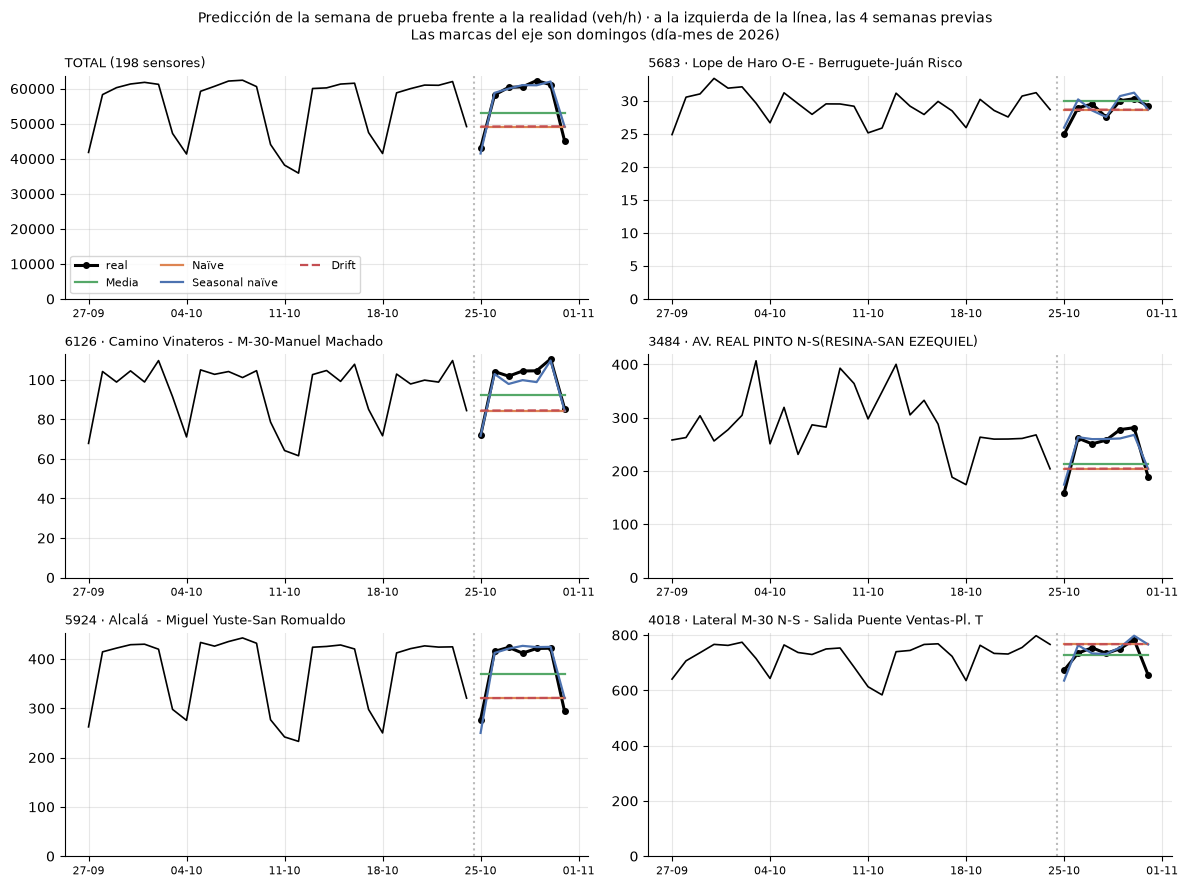

In [9]:
def dibujar(ax, uid, titulo):
    hist = train[(train["unique_id"] == uid) & (train["ds"] >= sd.TEST_INICIO - pd.Timedelta(days=28))]
    real = test[test["unique_id"] == uid]
    p = pred_test[pred_test["unique_id"] == uid]
    ax.plot(hist["ds"], hist["y"], color="black", linewidth=1.2)
    ax.plot(real["ds"], real["y"], color="black", linewidth=2.2, marker="o", markersize=4, label="real")
    for m in NOMBRES:
        ax.plot(p["ds"], p[m], color=COLOR[m], linewidth=1.6, linestyle="--" if m == "Drift" else "-", label=m)
    ax.axvline(sd.TEST_INICIO - pd.Timedelta(hours=12), color=GRIS, linestyle=":")
    ax.set_title(titulo, fontsize=9, loc="left")
    ax.set_ylim(0, None)
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.SU))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%m"))
    ax.tick_params(axis="x", labelsize=8)


nombres = sd.cargar_seleccion()["nombre"]
fig, ejes = plt.subplots(3, 2, figsize=(12, 9))
dibujar(ejes[0, 0], "TOTAL", "TOTAL (198 sensores)")
for ax, uid in zip(ejes.ravel()[1:], [MUESTRA[i] for i in (0, 2, 5, 7, 9)]):
    dibujar(ax, uid, f"{uid} · {nombres[int(uid)][:45]}")
ejes[0, 0].legend(fontsize=8, ncol=3, loc="lower left")
fig.suptitle("Predicción de la semana de prueba frente a la realidad (veh/h) · a la izquierda de la línea, las 4 semanas previas\n"
             "Las marcas del eje son domingos (día-mes de 2026)", fontsize=10)
plt.tight_layout()

**Lectura.**
- **El seasonal naïve gana con claridad**, en la prueba y en la ventana rodante, en el total y en casi todos los
  sensores. Es el único de los cuatro que reproduce la forma de la semana: baja el domingo, sube de lunes a viernes y
  vuelve a bajar el sábado.
- **Media, naïve y drift dibujan una línea casi recta.** No pueden acertar a la vez un miércoles y un domingo, y su
  error es varias veces mayor.
- **Naïve y drift son prácticamente el mismo método aquí**, hasta el punto de que sus líneas se tapan en los
  gráficos. El drift añade la pendiente media del histórico, y la serie no tiene tendencia (notebook 02), así que esa
  pendiente es casi cero.
- **El naïve depende del día en que se corta.** El último día de entrenamiento es un sábado, así que predice nivel
  de sábado para toda la semana y se queda corto de lunes a viernes.
- **La media** queda algo mejor que el naïve en el total porque el nivel medio de dos años está más cerca de un día
  laborable que el valor de un sábado, pero sigue sin ver el ciclo semanal.

**La prueba y la ventana rodante cuentan historias distintas en magnitud.** En el total, el seasonal naïve tiene un
MASE de 0,35 en la semana de prueba y de 0,95 en la ventana rodante: casi el triple. En veh/h, su error medio pasa
de un 2,5 % del nivel medio a un 6,9 %. La semana de prueba es una semana tranquila, sin festivos, parecida a la
anterior. La ventana rodante incluye Navidad, Semana Santa, agosto y los puentes, donde
copiar la semana pasada falla. Por eso el listón honesto es el de la ventana rodante.

## 5. El rival a batir y dónde falla

MASE medio del seasonal naïve en las 36 semanas sin festivo cerca: 0.54 · en las 16 con festivo en la semana o en la anterior: 1.88


,MASE,festivos
semana que empieza el domingo,,
2026-03-29,4.70,"en la semana: Jueves Santo, Viernes Santo"
2026-04-05,4.24,"en la anterior: Jueves Santo, Viernes Santo"
2025-12-21,3.21,en la semana: Navidad
2026-08-30,2.74,—
2026-01-04,2.53,en la semana: Reyes · en la anterior: Año Nuevo
2026-08-02,2.08,—
2025-12-07,1.63,en la semana: Inmaculada
2026-05-03,1.62,en la anterior: Día del Trabajo


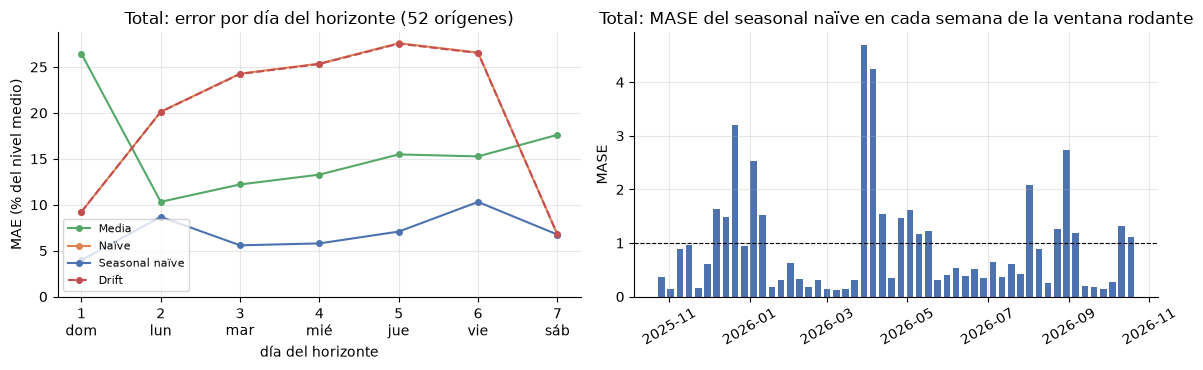

In [10]:
# Error por paso del horizonte (día 1 a día 7), en la ventana rodante, para el total
cv_total = cv[cv["unique_id"] == "TOTAL"].copy()
cv_total["paso"] = (cv_total["ds"] - cv_total["cutoff"]).dt.days
por_paso = cv_total.assign(**{m: (cv_total[m] - cv_total["y"]).abs() for m in NOMBRES}).groupby("paso")[NOMBRES].mean()
dia_paso = cv_total.groupby("paso")["ds"].first().dt.day_of_week.map(dict(enumerate(["lun", "mar", "mié", "jue", "vie", "sáb", "dom"])))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for m in NOMBRES:
    ax[0].plot(por_paso.index, por_paso[m] / nivel * 100, color=COLOR[m], marker="o", markersize=4,
               linestyle="--" if m == "Drift" else "-", label=m)
ax[0].set_xticks(por_paso.index, [f"{p}\n{dia_paso[p]}" for p in por_paso.index])
ax[0].set(title="Total: error por día del horizonte (52 orígenes)", xlabel="día del horizonte",
          ylabel="MAE (% del nivel medio)")
ax[0].set_ylim(0, None)
ax[0].legend(fontsize=8)

# Error del seasonal naïve semana a semana
sn = ev_origen[(ev_origen["unique_id"] == "TOTAL") & (ev_origen["metric"] == "mase")].set_index("cutoff")["Seasonal naïve"]
semana = sn.index + pd.Timedelta(days=1)
ax[1].bar(semana, sn.values, width=5, color=AZUL)
ax[1].axhline(1, color="black", linewidth=0.8, linestyle="--")
ax[1].set(title="Total: MASE del seasonal naïve en cada semana de la ventana rodante", ylabel="MASE")
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout()

festivos = pd.to_datetime(list(sd.FESTIVOS))
peores = sn.nlargest(8).to_frame("MASE")
peores.index = peores.index + pd.Timedelta(days=1)
peores.index.name = "semana que empieza el domingo"
def motivos(inicio):
    "Festivos dentro de la semana predicha o de la semana anterior (la que se copia)."
    dentro = [sd.FESTIVOS[f"{f:%Y-%m-%d}"] for f in festivos if inicio <= f < inicio + pd.Timedelta(days=7)]
    antes = [sd.FESTIVOS[f"{f:%Y-%m-%d}"] for f in festivos if inicio - pd.Timedelta(days=7) <= f < inicio]
    return ("en la semana: " + ", ".join(dentro) if dentro else "") + (" · " if dentro and antes else "") + \
           ("en la anterior: " + ", ".join(antes) if antes else "") or "—"
peores["festivos"] = [motivos(i) for i in peores.index]
sin_festivo = sn[[motivos(i + pd.Timedelta(days=1)) == "—" for i in sn.index]]
print(f"MASE medio del seasonal naïve en las {len(sin_festivo)} semanas sin festivo cerca: {sin_festivo.mean():.2f} · "
      f"en las {len(sn) - len(sin_festivo)} con festivo en la semana o en la anterior: {sn.drop(sin_festivo.index).mean():.2f}")
peores

,MASE mediano,MASE medio,sensores en los que es el mejor
Media,1.95,2.09,1
Naïve,2.15,2.22,4
Seasonal naïve,0.96,1.00,195
Drift,2.15,2.22,0


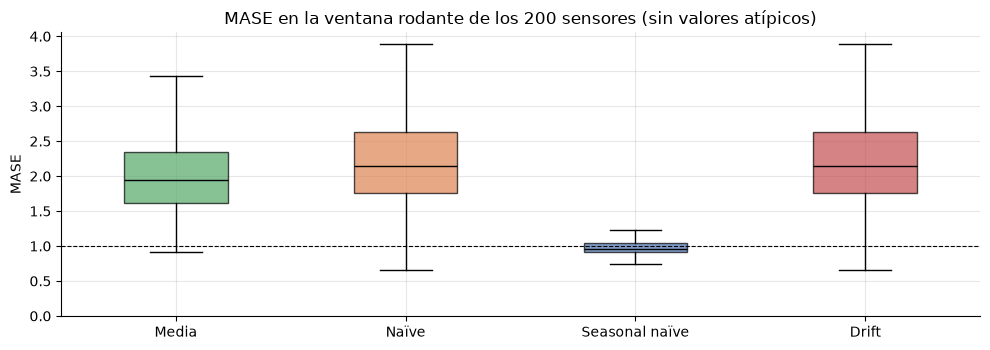

In [11]:
# ¿Se mantiene la conclusión en los 200 sensores? Misma ventana rodante sobre todas las series
train_todas = train_200[["unique_id", "ds", "y"]]
cv_200 = sf.cross_validation(df=train_todas, h=H, step_size=PASO, n_windows=N_VENTANAS).rename(columns=MODELOS)
partes = []
for origen in origenes:
    e = evaluate(cv_200[cv_200["cutoff"] == origen].drop(columns="cutoff"),
                 metrics=[partial(mase, seasonality=ESTACION)], train_df=train_todas[train_todas["ds"] <= origen], models=NOMBRES)
    partes.append(e)
mase_200 = pd.concat(partes).groupby("unique_id")[NOMBRES].mean()

fig, ax = plt.subplots(figsize=(10, 3.6))
cajas = ax.boxplot([mase_200[m] for m in NOMBRES], tick_labels=NOMBRES, patch_artist=True, showfliers=False,
                   medianprops={"color": "black"})
for caja, m in zip(cajas["boxes"], NOMBRES):
    caja.set(facecolor=COLOR[m], alpha=0.7)
ax.axhline(1, color="black", linewidth=0.8, linestyle="--")
ax.set(title="MASE en la ventana rodante de los 200 sensores (sin valores atípicos)", ylabel="MASE")
ax.set_ylim(0, None)
plt.tight_layout()

gana = mase_200.idxmin(axis=1).value_counts().reindex(NOMBRES, fill_value=0)
pd.DataFrame({"MASE mediano": mase_200.median(), "MASE medio": mase_200.mean(),
              "sensores en los que es el mejor": gana})

**El rival a batir es el seasonal naïve con `season_length = 7`**, en el total y en la gran mayoría de los sensores.

**¿En qué horizonte falla?**
- **No se degrada al alejarse del origen.** Su error no crece del día 1 al día 7, porque cada día copia el mismo día
  de la semana anterior, esté cerca o lejos. Lo que cambia es el día de la semana: el error va del 4 % un domingo al
  10 % un viernes, que es donde caen más festivos y puentes. El naïve y el drift, en cambio, aciertan el primer día
  (domingo tras sábado) y el último (sábado, como el origen), y se hunden de lunes a viernes.
- **Falla por semanas.** Su MASE medio es de 0,54 en las 36 semanas sin festivos cerca y de 1,88 en las 16 que
  tienen un festivo o siguen a una con festivo. Falla dos veces por cada festivo: la semana del festivo, porque copia
  un día normal, y la siguiente, porque copia el festivo.
- **Falla en los cambios de régimen.** Las dos peores semanas sin festivo son la primera de agosto y la última, la
  entrada y la salida de las vacaciones.

**En los 200 sensores la conclusión se mantiene:** el seasonal naïve es el mejor en 195. En los 5 restantes gana el
naïve o la media; son series con el ciclo semanal débil o con rupturas de nivel, donde mirar solo el último día
adapta antes. Son pocos, pero avisan de que el modelo global tendrá que manejar sensores con comportamientos
distintos.

**Lectura de negocio.** Para una semana corriente, saber qué pasó la semana anterior basta para prever el tráfico con
un error pequeño, y eso ya permite comparar días dentro de la semana. Pero las obras se planifican justo en las
semanas especiales (puentes, vacaciones), que son en las que este método falla. Ahí es donde un modelo mejor aporta
valor real.

## 6. Residuos del mejor baseline: ¿qué información deja sin usar?

El residuo del seasonal naïve dentro del entrenamiento es la diferencia entre cada día y el mismo día de la semana
anterior. Si el método lo aprovechara todo, los residuos serían ruido: sin estructura, sin autocorrelación y sin
relación con el calendario.

Contraste de Ljung-Box (hipótesis nula: los residuos no están autocorrelados)
    estadístico    p-valor
7         625.2 9.064e-131
14        699.1 3.975e-140


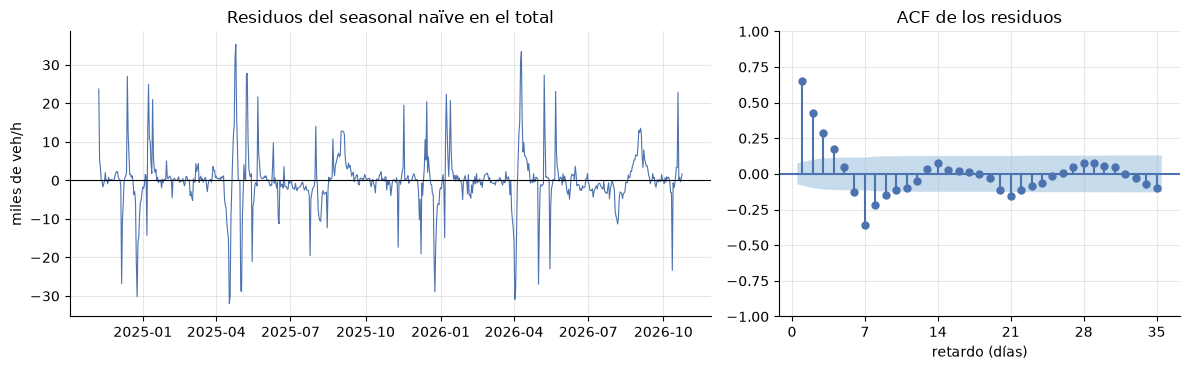

In [12]:
aj = ajustados[ajustados["unique_id"] == "TOTAL"].set_index("ds")
resid = (aj["y"] - aj["Seasonal naïve"]).dropna()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].plot(resid.index, resid / 1e3, color=AZUL, linewidth=0.8)
ax[0].axhline(0, color="black", linewidth=0.8)
ax[0].set(title="Residuos del seasonal naïve en el total", ylabel="miles de veh/h")
plot_acf(resid, lags=35, ax=ax[1], color=AZUL, vlines_kwargs={"colors": AZUL}, zero=False)
ax[1].set(title="ACF de los residuos", xlabel="retardo (días)")
ax[1].set_xticks(range(0, 36, 7))
plt.tight_layout()

lb = acorr_ljungbox(resid, lags=[7, 14], return_df=True)
print("Contraste de Ljung-Box (hipótesis nula: los residuos no están autocorrelados)")
print(lb.rename(columns={"lb_stat": "estadístico", "lb_pvalue": "p-valor"}).to_string(float_format=lambda x: f"{x:,.4g}"))

,dias,residuo_medio,error_abs_medio,% del error total
día normal,675,-17.29,"2,613.37",65.10
festivo,21,"-21,897.82","21,897.82",16.97
7 días después de un festivo,20,"24,291.27","24,291.27",17.93


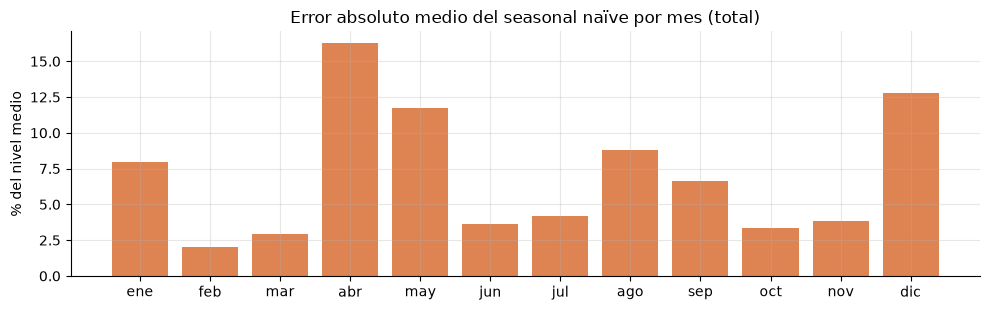

In [13]:
festivos = pd.to_datetime(list(sd.FESTIVOS))
tipo = pd.Series("día normal", index=resid.index)
tipo[resid.index.isin(festivos + pd.Timedelta(days=7))] = "7 días después de un festivo"
tipo[resid.index.isin(festivos)] = "festivo"
por_tipo = resid.groupby(tipo).agg(dias="size", residuo_medio="mean", error_abs_medio=lambda r: r.abs().mean())
por_tipo["% del error total"] = resid.abs().groupby(tipo).sum() / resid.abs().sum() * 100

por_mes = resid.abs().groupby(resid.index.month).mean()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar([["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"][m - 1] for m in por_mes.index],
       por_mes / nivel * 100, color=NARANJA)
ax.set(title="Error absoluto medio del seasonal naïve por mes (total)", ylabel="% del nivel medio")
plt.tight_layout()
por_tipo.loc[["día normal", "festivo", "7 días después de un festivo"]]

**Lectura.** Los residuos **no son ruido**. Queda información sin usar de tres tipos:

1. **Autocorrelación.** El contraste de Ljung-Box rechaza con claridad que los residuos sean independientes. La ACF
   es positiva en los primeros retardos y tiene un pico negativo en el 7. Lo primero indica **inercia**: si hoy hay
   menos tráfico que hace una semana, mañana probablemente también (vacaciones, cambios de nivel). Lo segundo es el
   rebote del propio método: un día anómalo genera un error hoy y otro de signo contrario a los 7 días.
2. **Calendario.** Los festivos y el día equivalente de la semana siguiente son un 6 % de los días y concentran el
   **35 % del error**. El residuo medio es muy negativo en el festivo (el método predice un día normal)
   y muy positivo siete días después (predice un festivo que ya no lo es).
3. **Época del año.** El error se concentra en los meses con festivos y transiciones: abril (Semana Santa),
   diciembre y enero (Navidad), mayo (tres festivos en Madrid) y agosto. En febrero, marzo, junio u octubre es
   varias veces menor.

**Lectura de negocio.** El margen de mejora está concentrado en pocas semanas, pero son las que más interesan para
programar obras. Y casi todo ese error depende de información que **se conoce de antemano**: el calendario.

## 7. Conclusiones y plan para E2

### Lo que deja E1

- **Serie.** 200 sensores urbanos, 2 años, frecuencia diaria, en formato largo y sin huecos (notebooks 01 y 02).
- **Partición.** Última semana como prueba (25–31 oct 2026) y ventana rodante de 52 orígenes semanales. Sin fuga:
  selección, umbrales e imputación usan solo el pasado.
- **Listón.** El rival a batir es el **seasonal naïve con `season_length = 7`**. Un modelo de E2 tiene que bajar su
  MASE en la **ventana rodante**, no solo en la semana de prueba, que es una semana fácil.
- **Dónde hay margen.** En las semanas con festivo, en las transiciones de vacaciones y en los sensores con rupturas
  de nivel.

### Plan para E2

**Modelo.** Un **modelo global con MLForecast**, como pide el encargo: un único modelo entrenado con las 200 series a
la vez. Se justifica porque los sensores comparten los mismos ciclos y los mismos festivos, y cada uno por separado
solo tiene dos años de datos y un puñado de festivos de los que aprender.

| Qué se probará | Por qué (qué residuo ataca) |
|---|---|
| **Retardos 7, 14, 21 y 28** | El ciclo semanal, que es lo que ya aprovecha el seasonal naïve. Con horizonte 7, son los retardos que se conocen para toda la semana predicha |
| **Medias móviles** de 7 y 28 días sobre el retardo 7 | La inercia que muestra la ACF de los residuos: el nivel reciente del sensor |
| **Día de la semana, mes y semana del año** | El ciclo semanal y el anual, y que el ciclo semanal se encoge en agosto |
| **Festivos, vísperas y puentes** | El mayor foco de error del baseline. Calendario oficial nacional, de la Comunidad y del municipio |
| **Vacaciones escolares, Navidad, Semana Santa y agosto** | Las transiciones de régimen, que no son festivos pero cambian el nivel durante semanas |
| **Normalización por serie** | Los niveles van de 30 a más de 1.000 veh/h; sin escalar, el modelo solo aprendería de los ejes grandes |
| **Lluvia** (previsión, no dato observado) | Posible efecto sobre el tráfico diario. Solo si se usa la **previsión** disponible el día en que se predice |

**Modelos.** Regresión lineal regularizada como referencia sencilla y **LightGBM** como modelo principal. Como
comparación local, **AutoETS** y **MSTL** de StatsForecast en la muestra de 10 series.

**Variables externas sin fuga.** Solo cuentan las que se conocerían el día de la predicción. El calendario cumple
siempre. La meteorología solo como previsión a 7 días, nunca como el dato observado.

**Evaluación.** La misma de este notebook, para que sea comparable: misma semana de prueba, misma ventana rodante de
52 orígenes y mismas métricas. Se evaluará sobre los 200 sensores y, por separado, en las semanas con festivo, que es
donde tiene que notarse la mejora.

**Riesgos que ya se conocen.** Los sensores con rupturas de nivel, donde el histórico antiguo engaña; la imputación,
que puede copiar un festivo; y la bajada del primer trimestre de 2026, que con dos años no se puede saber si se
repetirá.